# 05 - Multitask Deep Learning

One network predicts building, floor and coordinates from a Wi-Fi scan. We compare it with three
single-task networks (one per task) and with the Phase 1 Random Forest.

## Data

- Training file cleaned as in Phase 1 (duplicates and empty scans removed): 19,227 scans.
- Split into train (85%) and val (15%) by position, so scans from the same spot never end up on both
  sides. The official validation file (1,111 scans) is the test set.
- Inputs: RSSI with 100 replaced by -110 dBm, scaled to 0-1. Coordinates are standardised for training
  and converted back to metres for the errors. All scalers are fitted on train only.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.data_preprocessing import prepare_data
from src.models.multitask_net import MultitaskNet
from src.train_multitask import main, compare_over_seeds

data, prep = prepare_data()
print("Input features:", len(prep["used_waps"]))
print("Set sizes:", prep["sizes"])

Input features: 459
Set sizes: {'train': 16432, 'val': 2795, 'test': 1111}


## Model

```
RSSI (459) -> 512 -> 256 -> 128 (shared)
                              |-> building (3)
                              |-> floor (5)
                              |-> coordinates (2)
```

Each layer is Linear, LayerNorm and GELU, with dropout 0.2 after the first two. The loss is
cross-entropy for building and floor plus MSE for the coordinates, added with equal weights.
Adam, learning rate 0.001, batch size 128.

In [2]:
model = MultitaskNet(n_inputs=len(prep["used_waps"]))
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

MultitaskNet(
  (trunk): Sequential(
    (0): Sequential(
      (0): Linear(in_features=459, out_features=512, bias=True)
      (1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Dropout(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Linear(in_features=512, out_features=256, bias=True)
      (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Dropout(p=0.2, inplace=False)
    )
    (2): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
    )
  )
  (heads): ModuleDict(
    (building): Linear(in_features=128, out_features=3, bias=True)
    (floor): Linear(in_features=128, out_features=5, bias=True)
    (coords): Linear(in_features=128, out_features=2, bias=True)
  )
)
Parameters: 402826


## Training

The validation floor loss is lowest after about 2 epochs and then goes up, while floor accuracy stays
the same and the coordinate error keeps improving. Stopping on the validation loss would therefore stop
too early. Instead we keep the epoch with the best EvAAL competition score on val:

$$\text{score} = \text{mean error (m)} + 50 \times \text{building error rate} + 4 \times \text{mean floors off}$$

Training stops after 20 epochs without improvement. The cell below trains the multitask network and the
three single-task networks.

In [3]:
main()

Sizes: {'train': 16432, 'val': 2795, 'test': 1111}  Input features: 459
[multitask] epoch   1  train loss 0.4255  val loss 0.0945  val score 14.982  building_acc 1.000  floor_acc 0.979  floor_abs_diff 0.021  joint_acc 0.979  mean_error_m 14.896  median_error_m 13.036  p90_error_m 27.135
[multitask] epoch  10  train loss 0.0117  val loss 0.1439  val score 9.606  building_acc 1.000  floor_acc 0.967  floor_abs_diff 0.035  joint_acc 0.967  mean_error_m 9.468  median_error_m 8.057  p90_error_m 17.269
[multitask] epoch  20  train loss 0.0074  val loss 0.1294  val score 8.580  building_acc 1.000  floor_acc 0.973  floor_abs_diff 0.028  joint_acc 0.973  mean_error_m 8.470  median_error_m 7.406  p90_error_m 14.804
[multitask] epoch  30  train loss 0.0042  val loss 0.1226  val score 7.644  building_acc 1.000  floor_acc 0.972  floor_abs_diff 0.028  joint_acc 0.972  mean_error_m 7.532  median_error_m 6.389  p90_error_m 13.394
[multitask] epoch  40  train loss 0.0052  val loss 0.1119  val score 7.82

## Training curves

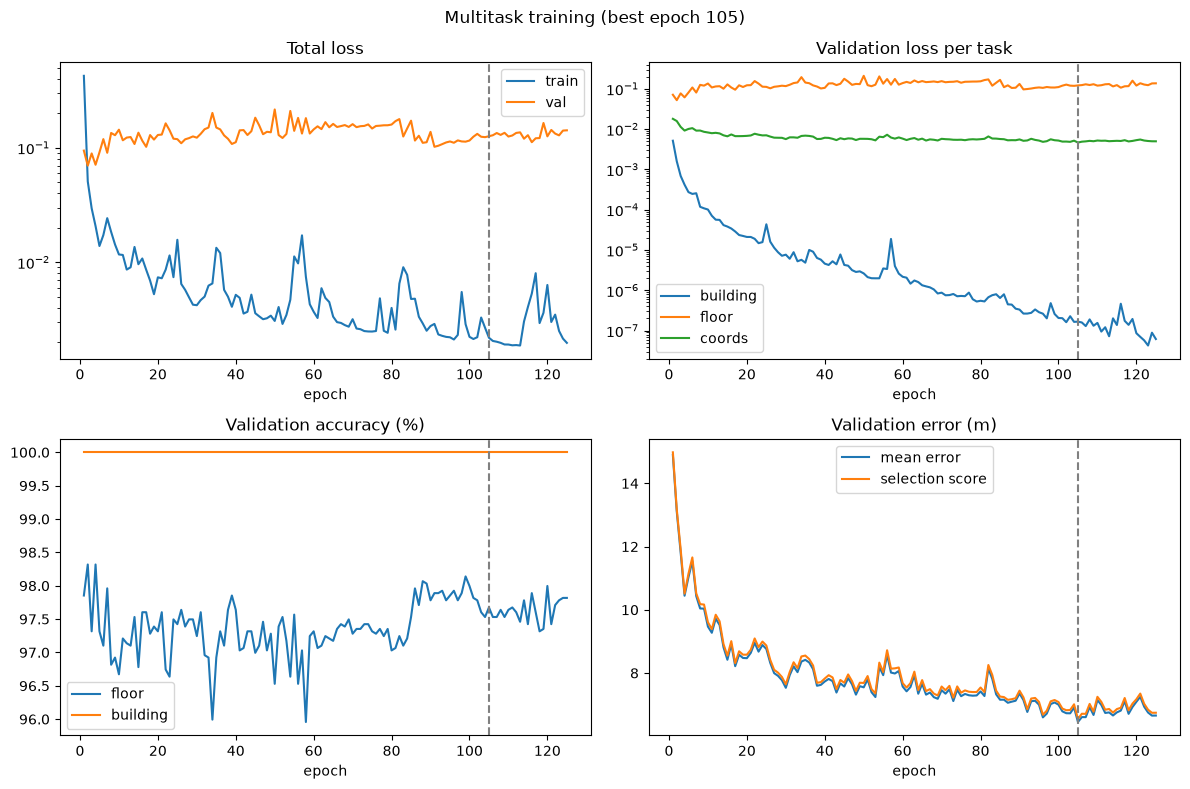

In [4]:
history = pd.read_csv("../results/metrics/multitask_training_history.csv")
best = history.loc[history["val_score"].idxmin(), "epoch"]
epochs = history["epoch"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(epochs, history["train_total_loss"], label="train")
axes[0, 0].plot(epochs, history["val_total_loss"], label="val")
axes[0, 0].set_title("Total loss")
axes[0, 0].set_yscale("log")

axes[0, 1].plot(epochs, history["val_building_loss"], label="building")
axes[0, 1].plot(epochs, history["val_floor_loss"], label="floor")
axes[0, 1].plot(epochs, history["val_coords_loss"], label="coords")
axes[0, 1].set_title("Validation loss per task")
axes[0, 1].set_yscale("log")

axes[1, 0].plot(epochs, history["val_floor_acc"] * 100, label="floor")
axes[1, 0].plot(epochs, history["val_building_acc"] * 100, label="building")
axes[1, 0].set_title("Validation accuracy (%)")

axes[1, 1].plot(epochs, history["val_mean_error_m"], label="mean error")
axes[1, 1].plot(epochs, history["val_score"], label="selection score")
axes[1, 1].set_title("Validation error (m)")

for ax in axes.flat:
    ax.axvline(best, color="grey", linestyle="--")
    ax.set_xlabel("epoch")
    ax.legend()

plt.suptitle(f"Multitask training (best epoch {best})")
plt.tight_layout()
plt.savefig("../results/figures/dl_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

The floor loss on val drifts up after the first few epochs, but the coordinate error keeps falling
until around epoch 100.

## Multitask vs single-task (test set)

Each single-task network predicts only one thing, so its numbers come from the network trained for
that task: building accuracy from `single_building`, floor accuracy from `single_floor`, and the errors
from `single_coords`.

In [5]:
metrics = ["building_acc", "floor_acc", "mean_error_m", "median_error_m", "p90_error_m"]
single_model = {"building_acc": "single_building", "floor_acc": "single_floor",
                "mean_error_m": "single_coords", "median_error_m": "single_coords",
                "p90_error_m": "single_coords"}

results = pd.read_csv("../results/metrics/dl_multitask_vs_single_task.csv")
test = results[results["split"] == "test"].set_index("model")

table = pd.DataFrame({
    "multitask": [test.loc["multitask", m] for m in metrics],
    "single-task": [test.loc[single_model[m], m] for m in metrics],
}, index=metrics)
table.round(4)

,multitask,single-task
building_acc,0.9973,1.0000
floor_acc,0.9100,0.9190
mean_error_m,8.9542,8.6614
median_error_m,7.0403,6.3669
p90_error_m,17.8700,17.1255


## Three random seeds

In [6]:
seed_file = "../results/metrics/dl_seed_comparison.csv"
try:
    seeds = pd.read_csv(seed_file)
except FileNotFoundError:
    seeds = compare_over_seeds()   

seed_test = seeds[seeds["split"] == "test"]
mean = seed_test.groupby("model")[metrics].mean()
std = seed_test.groupby("model")[metrics].std()

def mean_std(model, m):
    return f"{mean.loc[model, m]:.4f} ± {std.loc[model, m]:.4f}"

pd.DataFrame({
    "multitask": [mean_std("multitask", m) for m in metrics],
    "single-task": [mean_std(single_model[m], m) for m in metrics],
}, index=metrics)

,multitask,single-task
building_acc,0.9988 ± 0.0014,0.9997 ± 0.0005
floor_acc,0.9121 ± 0.0023,0.9151 ± 0.0068
mean_error_m,9.0262 ± 0.0976,8.5856 ± 0.1132
median_error_m,7.1701 ± 0.1396,6.3017 ± 0.1319
p90_error_m,17.6992 ± 0.2722,16.9102 ± 0.2467


## Comparison with the Random Forest (Phase 1)

In [7]:
rf = pd.read_csv("../results/metrics/eval_master_comparison.csv").set_index("Model").loc["Random Forest"]
rf_columns = ["Building Acc", "Floor Acc", "Mean Error (m)", "Median Error (m)", "P90 Error (m)"]

pd.DataFrame({
    "Random Forest": [rf[c] for c in rf_columns],
    "multitask": [test.loc["multitask", m] for m in metrics],
}, index=metrics).round(4)

,Random Forest,multitask
building_acc,0.9973,0.9973
floor_acc,0.8992,0.9100
mean_error_m,12.3023,8.9542
median_error_m,8.1481,7.0403
p90_error_m,29.5468,17.8700


## Summary

| Test set | Random Forest | Multitask (seed 42) |
|---|---|---|
| Building accuracy | 99.73% | 99.73% |
| Floor accuracy | 89.92% | 91.00% |
| Mean error | 12.30 m | 8.95 m |
| Median error | 8.15 m | 7.04 m |
| P90 error | 29.55 m | 17.87 m |

The network has the same building accuracy as the Random Forest, about one point higher floor accuracy,
and a mean error over 3 m lower.

Over three seeds, the multitask network (floor 91.21% ± 0.23, mean error 9.03 ± 0.10 m) does not beat
the single-task networks (floor 91.51% ± 0.68, mean error 8.59 ± 0.11 m). Floor accuracy is within the
seed-to-seed spread and the coordinate error is a bit worse. With equal loss weights the floor loss,
roughly 20 times larger than the coordinate loss, dominates the shared layers. Loss balancing (Member 3)
is the next thing to try.